# Projeto Lego

In [1]:
# Carregar os dados da URL no Pandas
import pandas as pd
url = 'https://raw.githubusercontent.com/KeithGalli/lego-analysis/master/datasets/lego_sets.csv'
df = pd.read_csv(url)

### Carregar bases de dados adicionais do Rebrickable

Aqui vamos carregar as tabelas relacionais do Rebrickable diretamente das fontes compactadas (`.csv.gz`) usando o Pandas.

In [2]:
import pandas as pd

# URLs dos principais arquivos disponibilizados pelo Rebrickable
urls = {
    'themes': 'https://cdn.rebrickable.com/media/downloads/themes.csv.gz',
    'sets': 'https://cdn.rebrickable.com/media/downloads/sets.csv.gz',
    'parts': 'https://cdn.rebrickable.com/media/downloads/parts.csv.gz',
    'inventories': 'https://cdn.rebrickable.com/media/downloads/inventories.csv.gz',
    'inventory_parts': 'https://cdn.rebrickable.com/media/downloads/inventory_parts.csv.gz',
    'colors': 'https://cdn.rebrickable.com/media/downloads/colors.csv.gz',
    'part_categories': 'https://cdn.rebrickable.com/media/downloads/part_categories.csv.gz',
    'elements': 'https://cdn.rebrickable.com/media/downloads/elements.csv.gz',
    'part_relationships': 'https://cdn.rebrickable.com/media/downloads/part_relationships.csv.gz',
    'minifigs': 'https://cdn.rebrickable.com/media/downloads/minifigs.csv.gz',
    'inventory_minifigs': 'https://cdn.rebrickable.com/media/downloads/inventory_minifigs.csv.gz',
    'inventory_sets': 'https://cdn.rebrickable.com/media/downloads/inventory_sets.csv.gz'
}

# Dicionário para armazenar os DataFrames
dataframes = {}

for name, url in urls.items():
    try:
        print(f"Carregando {name}...")
        # O pandas lida automaticamente com a descompressão de arquivos .gz
        dataframes[name] = pd.read_csv(url)
        print(f"{name.capitalize()} carregado com sucesso! Shape: {dataframes[name].shape}")
    except Exception as e:
        print(f"Erro ao carregar {name}: {e}")

# Exemplo de exibição de um dos datasets
if 'themes' in dataframes:
    display(dataframes['themes'].head())

Carregando themes...
Themes carregado com sucesso! Shape: (496, 3)
Carregando sets...
Sets carregado com sucesso! Shape: (28544, 6)
Carregando parts...
Parts carregado com sucesso! Shape: (64900, 4)
Carregando inventories...
Inventories carregado com sucesso! Shape: (47789, 3)
Carregando inventory_parts...
Inventory_parts carregado com sucesso! Shape: (1567180, 6)
Carregando colors...
Colors carregado com sucesso! Shape: (275, 8)
Carregando part_categories...
Part_categories carregado com sucesso! Shape: (76, 2)
Carregando elements...
Elements carregado com sucesso! Shape: (114661, 4)
Carregando part_relationships...
Part_relationships carregado com sucesso! Shape: (37537, 3)
Carregando minifigs...
Minifigs carregado com sucesso! Shape: (17293, 4)
Carregando inventory_minifigs...
Inventory_minifigs carregado com sucesso! Shape: (25903, 3)
Carregando inventory_sets...
Inventory_sets carregado com sucesso! Shape: (5217, 3)


,id,name,parent_id
0,1,Technic,NaN
1,3,Competition,1.0
2,4,Expert Builder,1.0
3,16,RoboRiders,1.0
4,17,Speed Slammers,1.0


In [3]:
dataframes['minifigs'].sample


<bound method NDFrame.sample of           fig_num                                               name  \
0      fig-000001                                 Toy Store Employee   
1      fig-000002                                       Customer Kid   
2      fig-000003                              Assassin Droid, White   
3      fig-000004           Man, White Torso, Black Legs, Brown Hair   
4      fig-000005                    Captain America with Short Legs   
...           ...                                                ...   
17288  fig-018220                           LEGO Store Hangzhou, Man   
17289  fig-018221                         LEGO Store Hangzhou, Woman   
17290  fig-018222       Pizzaria Waiter, White Torso, Warm Pink Legs   
17291  fig-018223  Woman, Light Bluish Grey/Bright Green Wetsuit,...   
17292  fig-018224               Kid Adventurer, Dark Brown Suit, Hat   

       num_parts                                            img_url  
0              4  https://cdn.rebrickable.com/media/sets/fig-000...  
1              4  https://cdn.rebrickable.com/media/sets/fig-000...  
2              8  https://cdn.rebrickable.com/media/sets/fig-000...  
3              4  https://cdn.rebrickable.com/media/sets/fig-000...  
4              3  https://cdn.rebrickable.com/media/sets/fig-000...  
...          ...                                                ...  
17288          4  https://cdn.rebrickable.com/media/sets/fig-018...  
17289          4  https://cdn.rebrickable.com/media/sets/fig-018...  
17290          4  https://cdn.rebrickable.com/media/sets/fig-018...  
17291          4  https://cdn.rebrickable.com/media/sets/fig-018...  
17292          4  https://cdn.rebrickable.com/media/sets/fig-018...  

[17293 rows x 4 columns]>

### Salvar DataFrames no Formato Parquet

Vamos iterar sobre o dicionário `dataframes` e salvar cada um deles como um arquivo `.parquet` de forma individual.

In [4]:
import os

# Criar um diretório para organizar os arquivos parquet
os.makedirs('lego_parquet', exist_ok=True)

for name, df in dataframes.items():
    try:
        output_path = f'lego_parquet/{name}.parquet'
        # Salva o DataFrame no formato Parquet (requer pyarrow ou fastparquet instalado)
        df.to_parquet(output_path, index=False)
        print(f"DataFrame '{name}' salvo com sucesso em: {output_path} (Tamanho: {os.path.getsize(output_path) / (1024*1024):.2f} MB)")
    except Exception as e:
        print(f"Erro ao salvar {name} em parquet: {e}")

DataFrame 'themes' salvo com sucesso em: lego_parquet/themes.parquet (Tamanho: 0.01 MB)
DataFrame 'sets' salvo com sucesso em: lego_parquet/sets.parquet (Tamanho: 0.84 MB)
DataFrame 'parts' salvo com sucesso em: lego_parquet/parts.parquet (Tamanho: 1.86 MB)
DataFrame 'inventories' salvo com sucesso em: lego_parquet/inventories.parquet (Tamanho: 0.61 MB)
DataFrame 'inventory_parts' salvo com sucesso em: lego_parquet/inventory_parts.parquet (Tamanho: 17.20 MB)
DataFrame 'colors' salvo com sucesso em: lego_parquet/colors.parquet (Tamanho: 0.01 MB)
DataFrame 'part_categories' salvo com sucesso em: lego_parquet/part_categories.parquet (Tamanho: 0.00 MB)
DataFrame 'elements' salvo com sucesso em: lego_parquet/elements.parquet (Tamanho: 1.70 MB)
DataFrame 'part_relationships' salvo com sucesso em: lego_parquet/part_relationships.parquet (Tamanho: 0.37 MB)
DataFrame 'minifigs' salvo com sucesso em: lego_parquet/minifigs.parquet (Tamanho: 0.56 MB)
DataFrame 'inventory_minifigs' salvo com sucess

In [5]:
!ls -l lego_parquet/


total 23992
-rw-r--r-- 1 root root    13542 Oct 18 20:00 colors.parquet
-rw-r--r-- 1 root root  1780614 Oct 18 20:00 elements.parquet
-rw-r--r-- 1 root root   642553 Oct 18 20:00 inventories.parquet
-rw-r--r-- 1 root root   215834 Oct 18 20:00 inventory_minifigs.parquet
-rw-r--r-- 1 root root 18038814 Oct 18 20:00 inventory_parts.parquet
-rw-r--r-- 1 root root    43421 Oct 18 20:00 inventory_sets.parquet
-rw-r--r-- 1 root root   588898 Oct 18 20:00 minifigs.parquet
-rw-r--r-- 1 root root     3233 Oct 18 20:00 part_categories.parquet
-rw-r--r-- 1 root root   386637 Oct 18 20:00 part_relationships.parquet
-rw-r--r-- 1 root root  1945416 Oct 18 20:00 parts.parquet
-rw-r--r-- 1 root root   879157 Oct 18 20:00 sets.parquet
-rw-r--r-- 1 root root    10615 Oct 18 20:00 themes.parquet


### Instalar e Configurar o PySpark

Instalamos a biblioteca do PySpark no ambiente do Google Colab.

In [6]:
!pip install pyspark

### Iniciar SparkSession e Carregar Parquets como RDDs

In [7]:
from pyspark.sql import SparkSession
import os

# Inicializa a sessão do Spark
spark = SparkSession.builder \
    .appName("AnaliseLego") \
    .getOrCreate()

# Pasta onde estão os parquets
parquet_dir = 'lego_parquet'
rdds = {}

# Carrega cada parquet como DataFrame do Spark e converte para RDD
for file_name in os.listdir(parquet_dir):
    if file_name.endswith('.parquet'):
        name = file_name.replace('.parquet', '')
        file_path = os.path.join(parquet_dir, file_name)

        try:
            # Carrega o arquivo Parquet como Spark DataFrame
            spark_df = spark.read.parquet(file_path)
            # Converte o DataFrame do Spark em RDD
            rdds[name] = spark_df.rdd
            print(f"Parquet '{name}' carregado e convertido para RDD com sucesso!")
        except Exception as e:
            print(f"Erro ao carregar {name}: {e}")

# Demonstração simples pegando um exemplo de registro do RDD 'themes'
if 'themes' in rdds:
    print("\nExemplo de registro no RDD 'themes':")
    print(rdds['themes'].take(5))

Parquet 'inventories' carregado e convertido para RDD com sucesso!
Parquet 'elements' carregado e convertido para RDD com sucesso!
Parquet 'parts' carregado e convertido para RDD com sucesso!
Parquet 'inventory_minifigs' carregado e convertido para RDD com sucesso!
Parquet 'minifigs' carregado e convertido para RDD com sucesso!
Parquet 'inventory_parts' carregado e convertido para RDD com sucesso!
Parquet 'colors' carregado e convertido para RDD com sucesso!
Parquet 'themes' carregado e convertido para RDD com sucesso!
Parquet 'part_relationships' carregado e convertido para RDD com sucesso!
Parquet 'inventory_sets' carregado e convertido para RDD com sucesso!
Parquet 'sets' carregado e convertido para RDD com sucesso!
Parquet 'part_categories' carregado e convertido para RDD com sucesso!

Exemplo de registro no RDD 'themes':
[Row(id=1, name='Technic', parent_id=None), Row(id=3, name='Competition', parent_id=1.0), Row(id=4, name='Expert Builder', parent_id=1.0), Row(id=16, name='RoboRi

### Criar Views Temporárias a partir dos RDDs para consultas SQL

Como os RDDs foram criados a partir de DataFrames lidos do Parquet, eles possuem a estrutura de `Row` com nomes de colunas definidos. Podemos convertê-los de volta para DataFrames do Spark e registrá-los como views SQL temporárias.

In [8]:
# Iterar sobre o dicionário de RDDs, recriar os DataFrames e registrá-los como views temporárias
for name, rdd in rdds.items():
    try:
        # Cria o DataFrame a partir do RDD
        spark_df_temp = spark.createDataFrame(rdd)
        # Registra como view temporária com o mesmo nome original
        spark_df_temp.createOrReplaceTempView(name)
        print(f"View temporária SQL '{name}' registrada com sucesso!")
    except Exception as e:
        print(f"Erro ao registrar a view SQL para {name}: {e}")

View temporária SQL 'inventories' registrada com sucesso!
View temporária SQL 'elements' registrada com sucesso!
View temporária SQL 'parts' registrada com sucesso!
View temporária SQL 'inventory_minifigs' registrada com sucesso!
View temporária SQL 'minifigs' registrada com sucesso!
View temporária SQL 'inventory_parts' registrada com sucesso!
View temporária SQL 'colors' registrada com sucesso!
View temporária SQL 'themes' registrada com sucesso!
View temporária SQL 'part_relationships' registrada com sucesso!
View temporária SQL 'inventory_sets' registrada com sucesso!
View temporária SQL 'sets' registrada com sucesso!
View temporária SQL 'part_categories' registrada com sucesso!


### Testar consultas Spark SQL

Agora você já pode executar consultas SQL diretamente nas tabelas usando `spark.sql()`!

In [9]:
# Exemplo de query SQL: Contar a quantidade de sets por ano e ordenar decrescente
query_exemplo = """
SELECT year, COUNT(*) as total_sets
FROM sets
GROUP BY year
ORDER BY total_sets DESC
LIMIT 10
"""

resultado = spark.sql(query_exemplo)
resultado.show()

+----+----------+
|year|total_sets|
+----+----------+
|2026|      1556|
|2025|      1436|
|2023|      1406|
|2021|      1369|
|2022|      1368|
|2024|      1304|
|2019|      1143|
|2020|      1136|
|2017|      1122|
|2018|      1082|
+----+----------+



In [10]:
# Listar Darth Vader em minifigs
query_darth_vader = """
SELECT
  minifigs.fig_num,
  minifigs.name AS minifig_name
FROM minifigs
WHERE minifigs.name LIKE '%Darth Vader%'
"""

resultado_darth_vader = spark.sql(query_darth_vader)

In [11]:
# Quais os sets tem a minifig do Darth Vader?
query_set_com_darth_vader = """
SELECT *
FROM
  sets,
  inventories,
  minifigs,
  inventory_minifigs
WHERE
  sets.set_num = inventories.set_num
  AND inventories.id = inventory_minifigs.inventory_id
  AND inventory_minifigs.fig_num = minifigs.fig_num
  AND minifigs.name LIKE '%Darth Vader%'
"""

resultado_set_com_darth_vader = spark.sql(query_set_com_darth_vader)
resultado_set_com_darth_vader.show()
resultado_set_com_darth_vader.count()

+-----------+--------------------+----+--------+---------+--------------------+------+-------+-----------+----------+--------------------+---------+--------------------+------------+----------+--------+
|    set_num|                name|year|theme_id|num_parts|             img_url|    id|version|    set_num|   fig_num|                name|num_parts|             img_url|inventory_id|   fig_num|quantity|
+-----------+--------------------+----+--------+---------+--------------------+------+-------+-----------+----------+--------------------+---------+--------------------+------------+----------+--------+
|   852715-1|Star Wars Magnet Set|2009|     734|       19|https://cdn.rebri...| 16006|      1|   852715-1|fig-003686|Darth Vader, Damaged|        4|https://cdn.rebri...|       16006|fig-003686|       1|
|     7672-1|        Rogue Shadow|2008|     158|      482|https://cdn.rebri...| 12807|      1|     7672-1|fig-003686|Darth Vader, Damaged|        4|https://cdn.rebri...|       12807|fig-00

67

In [12]:
# Quais os maiores sets de Lego
query_big_sets = """
SELECT
  sets.name,
  sets.num_parts
FROM sets
ORDER BY sets.num_parts DESC
LIMIT 10
"""

resultado_big_sets = spark.sql(query_big_sets)
resultado_big_sets.show()

+--------------------+---------+
|                name|num_parts|
+--------------------+---------+
|           World Map|    11695|
|        Eiffel Tower|    10001|
|The Ultimate Batt...|    10001|
|             Titanic|     9092|
|           Colosseum|     9036|
|          Death Star|     9031|
|The Lord of the R...|     8278|
|   Millennium Falcon|     7541|
|Venusaur, Chariza...|     6838|
|               AT-AT|     6785|
+--------------------+---------+



### Maiores Conjuntos de Lego (com Temas)

Vamos rodar uma consulta que une a tabela de `sets` com a tabela de `themes` para entender quais são os maiores conjuntos de Lego já lançados e a quais linhas eles pertencem.

In [13]:
query_maiores_sets_temas = """
SELECT
  s.set_num,
  s.name AS set_name,
  s.year,
  s.num_parts,
  t.name AS theme_name
FROM sets s
LEFT JOIN themes t ON s.theme_id = t.id
ORDER BY s.num_parts DESC
LIMIT 15
"""

spark.sql(query_maiores_sets_temas).show(truncate=False)

+--------+-----------------------------------+----+---------+-------------------------+
|set_num |set_name                           |year|num_parts|theme_name               |
+--------+-----------------------------------+----+---------+-------------------------+
|31203-1 |World Map                          |2021|11695    |LEGO Art                 |
|10307-1 |Eiffel Tower                       |2022|10001    |Icons                    |
|BIGBOX-1|The Ultimate Battle for Chima      |2015|10001    |Legends of Chima         |
|10294-1 |Titanic                            |2021|9092     |Icons                    |
|10276-1 |Colosseum                          |2020|9036     |Icons                    |
|75419-1 |Death Star                         |2025|9031     |Ultimate Collector Series|
|11377-1 |The Lord of the Rings: Minas Tirith|2026|8278     |Icons                    |
|75192-1 |Millennium Falcon                  |2017|7541     |Ultimate Collector Series|
|72153-1 |Venusaur, Charizard an

In [14]:
# Quais os sets com mais minifigs?
query_set_com_mais_minifigs = """
SELECT
  sets.set_num,
  sets.name AS set_name,
  COUNT(inventory_minifigs.fig_num) AS num_minifigs
  FROM sets
  LEFT JOIN inventories ON sets.set_num = inventories.set_num
  LEFT JOIN inventory_minifigs ON inventories.id = inventory_minifigs.inventory_id
  GROUP BY sets.set_num, sets.name
  ORDER BY num_minifigs DESC
  LIMIT 10
"""

resultado_set_com_mais_minifigs = spark.sql(query_set_com_mais_minifigs)
resultado_set_com_mais_minifigs.show(truncate=False)

+--------+----------------------------------+------------+
|set_num |set_name                          |num_minifigs|
+--------+----------------------------------+------------+
|BIGBOX-1|The Ultimate Battle for Chima     |69          |
|71741-1 |NINJAGO City Gardens              |66          |
|76178-1 |Daily Bugle                       |50          |
|3409-1  |Championship Challenge            |48          |
|9348-1  |Community Minifigures             |44          |
|9349-1  |Fairytale and Historic Minifigures|44          |
|10188-1 |Death Star                        |42          |
|75419-1 |Death Star                        |39          |
|75290-1 |Mos Eisley Cantina                |38          |
|9247-1  |Community Workers                 |31          |
+--------+----------------------------------+------------+



In [15]:
# Existem outros BIGBOX?
query_for_big_box = """
SELECT
  sets.set_num,
  sets.name
FROM sets
WHERE sets.set_num LIKE '%BIG%'
"""

spark.sql(query_for_big_box).show(truncate=False)

+--------+-----------------------------+
|set_num |name                         |
+--------+-----------------------------+
|BIGBOX-1|The Ultimate Battle for Chima|
+--------+-----------------------------+



In [16]:
# Quais os materiais mais comuns nas peças?
query_materials = """
SELECT
    p.part_material,
    SUM(ip.quantity) AS quantidade_pecas
FROM parts p
JOIN inventory_parts ip ON p.part_num = ip.part_num
GROUP BY p.part_material
ORDER BY quantidade_pecas DESC
"""

spark.sql(query_materials).show()

+----------------+----------------+
|   part_material|quantidade_pecas|
+----------------+----------------+
|         Plastic|         5247119|
|          Rubber|           39593|
| Cardboard/Paper|            4204|
|           Cloth|            3027|
|Flexible Plastic|             803|
|           Metal|             403|
|            Foam|             271|
+----------------+----------------+



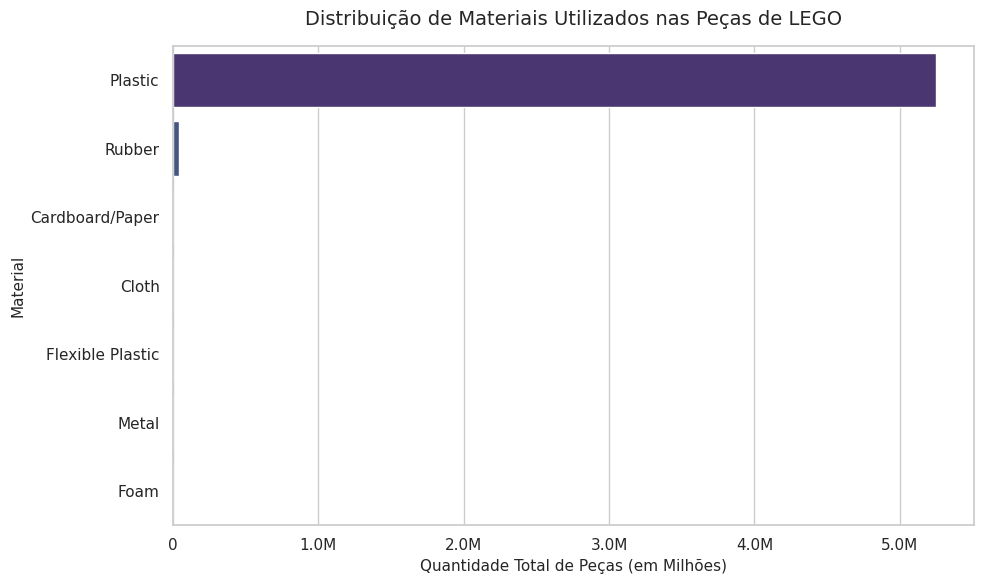

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Converte os resultados do Spark SQL para um DataFrame do Pandas
df_materials = spark.sql(query_materials).toPandas()

# Define o tamanho e estilo da figura
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Cria o gráfico de barras
ax = sns.barplot(
    x="quantidade_pecas",
    y="part_material",
    data=df_materials,
    palette="viridis",
    hue="part_material",
    legend=False
)

# Configura os títulos e eixos
plt.title("Distribuição de Materiais Utilizados nas Peças de LEGO", fontsize=14, pad=15)
plt.xlabel("Quantidade Total de Peças (em Milhões)", fontsize=11)
plt.ylabel("Material", fontsize=11)

# Formata o eixo x para exibir os números de forma simplificada em milhões (M)
import matplotlib.ticker as ticker
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x*1e-6:.1f}M' if x >= 1e6 else f'{int(x)}'))

plt.tight_layout()
plt.show()

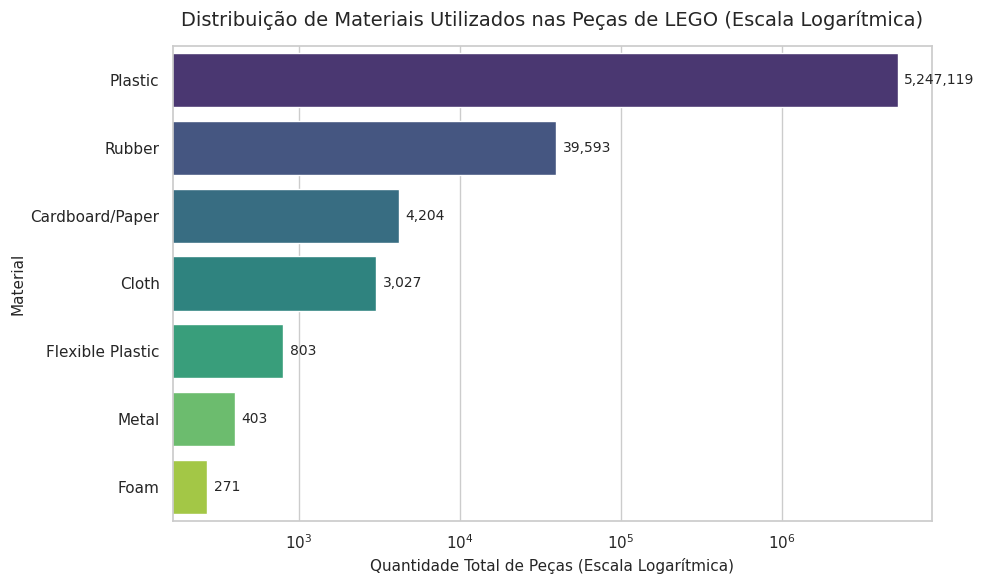

In [18]:
# Define o tamanho e estilo do novo gráfico
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Cria o gráfico de barras
ax = sns.barplot(
    x="quantidade_pecas",
    y="part_material",
    data=df_materials,
    palette="viridis",
    hue="part_material",
    legend=False
)

# Aplica a escala logarítmica no eixo X
ax.set_xscale("log")

# Configura os títulos e eixos
plt.title("Distribuição de Materiais Utilizados nas Peças de LEGO (Escala Logarítmica)", fontsize=14, pad=15)
plt.xlabel("Quantidade Total de Peças (Escala Logarítmica)", fontsize=11)
plt.ylabel("Material", fontsize=11)

# Exibe os valores exatos de cada barra para facilitar a leitura na escala log
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(
            width * 1.1,
            p.get_y() + p.get_height() / 2,
            f'{int(width):,}',
            va='center',
            fontsize=10
        )

plt.tight_layout()
plt.show()

In [19]:
# Consulta para analisar a quantidade de peças (num_parts) que as minifiguras possuem
query_minifig_parts = """
SELECT
    num_parts,
    COUNT(*) AS quantidade_minifigs
FROM minifigs
GROUP BY num_parts
ORDER BY num_parts ASC
"""

# Executa a query e exibe o resultado
resultado_minifig_parts = spark.sql(query_minifig_parts)
resultado_minifig_parts.show(truncate=False)


+---------+-------------------+
|num_parts|quantidade_minifigs|
+---------+-------------------+
|0        |1                  |
|1        |2                  |
|2        |130                |
|3        |1113               |
|4        |9760               |
|5        |3891               |
|6        |1044               |
|7        |375                |
|8        |146                |
|9        |100                |
|10       |107                |
|11       |38                 |
|12       |41                 |
|13       |55                 |
|14       |62                 |
|15       |37                 |
|16       |27                 |
|17       |25                 |
|18       |19                 |
|19       |13                 |
+---------+-------------------+
only showing top 20 rows


In [20]:
# Também podemos calcular algumas estatísticas gerais sobre as peças das minifiguras
query_estatisticas_minifigs = """
SELECT
    MIN(num_parts) AS min_pecas,
    MAX(num_parts) AS max_pecas,
    AVG(num_parts) AS media_pecas,
    SUM(num_parts) AS total_pecas_acumuladas
FROM minifigs
"""

spark.sql(query_estatisticas_minifigs).show()


+---------+---------+-----------------+----------------------+
|min_pecas|max_pecas|      media_pecas|total_pecas_acumuladas|
+---------+---------+-----------------+----------------------+
|        0|      156|5.271150176371942|                 91154|
+---------+---------+-----------------+----------------------+



In [29]:
# Qual a cor predominante nas peças das minifigs?
query_color_minifigs = """
SELECT
    c.name AS cor_nome,
    SUM(ip.quantity) AS quantidade_total
FROM inventory_minifigs im
JOIN inventory_parts ip
    ON im.inventory_id = ip.inventory_id
JOIN colors c
    ON ip.color_id = c.id
WHERE ip.is_spare = false
GROUP BY c.name
ORDER BY quantidade_total DESC
LIMIT 15
"""

resultado_color_minifigs = spark.sql(query_color_minifigs)
resultado_color_minifigs.show(truncate=False)

+-----------------+----------------+
|cor_nome         |quantidade_total|
+-----------------+----------------+
|Black            |2757499         |
|Light Bluish Gray|2552808         |
|Dark Bluish Gray |1858437         |
|White            |1631230         |
|Reddish Brown    |1011283         |
|Tan              |811156          |
|Red              |761904          |
|Dark Tan         |416700          |
|Blue             |387122          |
|Yellow           |369833          |
|Pearl Gold       |287330          |
|Green            |236443          |
|Medium Nougat    |220781          |
|Dark Red         |211792          |
|Dark Blue        |210836          |
+-----------------+----------------+



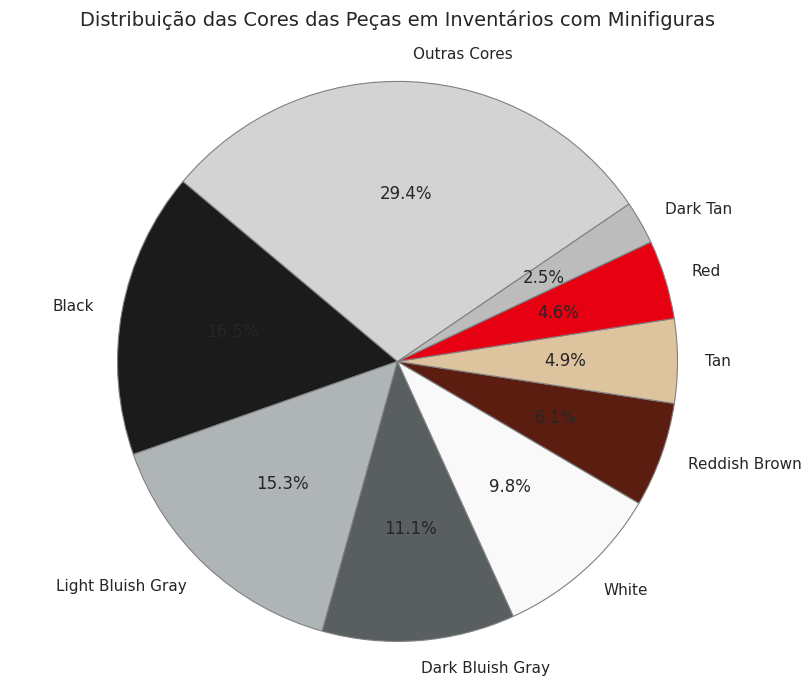

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

# Define a query SQL para buscar as cores das peças das minifiguras
# Buscar as cores das peças dos inventários que contêm minifiguras
query_color_minifigs = """
SELECT
    c.name AS cor_nome,
    SUM(ip.quantity) AS quantidade_total
FROM inventory_minifigs im
JOIN inventory_parts ip
    ON im.inventory_id = ip.inventory_id
JOIN colors c
    ON ip.color_id = c.id
WHERE ip.is_spare = false
GROUP BY c.name
ORDER BY quantidade_total DESC
"""

# Executa a query das cores e converte para um DataFrame do Pandas
df_colors = spark.sql(query_color_minifigs).toPandas()

# Agrupa cores menos comuns sob a categoria 'Outros' para não sobrecarregar o gráfico
top_n = 8
df_top_colors = df_colors.head(top_n).copy()
outros_total = df_colors.iloc[top_n:]['quantidade_total'].sum()

if outros_total > 0:
    # Cria uma nova linha para representar o grupo 'Outros'
    linha_outros = pd.DataFrame([{'cor_nome': 'Outras Cores', 'quantidade_total': outros_total}])
    df_top_colors = pd.concat([df_top_colors, linha_outros], ignore_index=True)

# Define o tamanho da figura
plt.figure(figsize=(10, 8))

# Mapeamento simples de nomes de cores em inglês para cores hexadecimais para deixar o gráfico fiel
color_map = {
    'Black': '#1B1B1B', 'White': '#F9F9F9', 'Red': '#E60012', 'Yellow': '#F2CD37',
    'Blue': '#0055A5', 'Dark Bluish Gray': '#595E60', 'Light Bluish Gray': '#AFB5B7',
    'Reddish Brown': '#5C1D11', 'Tan': '#DEC39F', 'Green': '#008542', 'Dark Gray': '#3E3E3E',
    'Orange': '#F57D11', 'Lime': '#BBE90B', 'Pink': '#FA96C3', 'Outras Cores': '#D3D3D3'
}

plot_colors = [color_map.get(cor, '#BCBCBC') for cor in df_top_colors['cor_nome']]

# Cria o gráfico de pizza
plt.pie(
    df_top_colors['quantidade_total'],
    labels=df_top_colors['cor_nome'],
    autopct='%1.1f%%',
    startangle=140,
    colors=plot_colors,
    wedgeprops={'edgecolor': 'gray', 'linewidth': 0.8, 'antialiased': True}
)

plt.title("Distribuição das Cores das Peças em Inventários com Minifiguras", fontsize=14, pad=20)
plt.axis('equal')  # Garante que a pizza seja desenhada como um círculo completo
plt.show()

### Análise de Cores Específicas das Cabeças de Minifiguras (`Minifig Heads`)

Vamos identificar quais são as cores mais utilizadas nas cabeças das minifiguras de LEGO. Para isso, faremos uma junção que filtra as peças pertencentes especificamente à categoria de cabeças de minifiguras.

In [31]:
# Identificar a categoria correspondente a cabeças e buscar a distribuição de cores
query_cabecas_cores = """
SELECT
    c.name AS cor_nome,
    SUM(ip.quantity) AS quantidade_total
FROM inventory_minifigs im
JOIN inventory_parts ip ON im.inventory_id = ip.inventory_id
JOIN parts p ON ip.part_num = p.part_num
JOIN part_categories pc ON p.part_cat_id = pc.id
JOIN colors c ON ip.color_id = c.id
WHERE pc.name LIKE '%Minifig Heads%'
  AND ip.is_spare = false
GROUP BY c.name
ORDER BY quantidade_total DESC
LIMIT 15
"""

df_cabecas = spark.sql(query_cabecas_cores).toPandas()
display(df_cabecas)

,cor_nome,quantidade_total
0,White,2513
1,Trans-Clear,1480
2,Trans-Red,1020
3,Trans-Light Blue,981
4,Black,927
5,Yellow,543
6,Pearl Gold,527
7,Trans-Yellow,449
8,Trans-Neon Orange,420
9,Medium Nougat,395


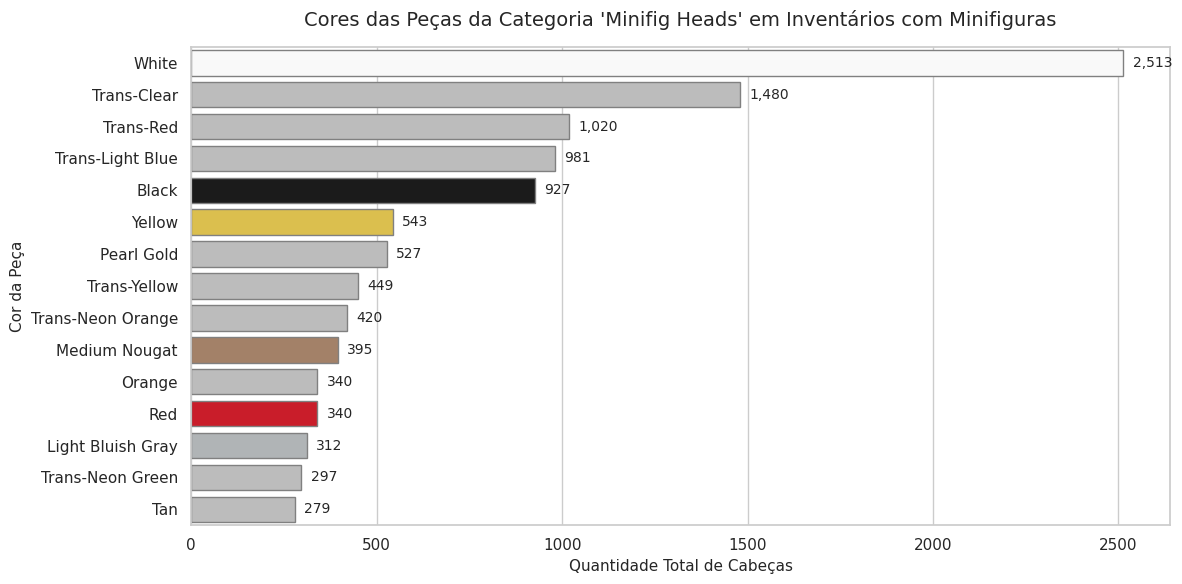

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

# Gerar gráfico de barras para visualizar as cores das cabeças
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Mapear cores para aproximar do visual real
color_map_heads = {
    'Yellow': '#F2CD37',
    'White': '#F9F9F9',
    'Light Flesh': '#F6D5C8',
    'Flesh': '#D6A28C',
    'Dark Flesh': '#7C4F3B',
    'Medium Nougat': '#AD805E',
    'Black': '#1B1B1B',
    'Red': '#E60012',
    'Blue': '#0055A5',
    'Light Bluish Gray': '#AFB5B7',
    'Dark Bluish Gray': '#595E60'
}

# Cores das barras com base no mapa ou cinza neutro se não mapeado
bar_colors = [color_map_heads.get(cor, '#BCBCBC') for cor in df_cabecas['cor_nome']]

ax = sns.barplot(
    x="quantidade_total",
    y="cor_nome",
    data=df_cabecas,
    palette=bar_colors,
    hue="cor_nome",
    legend=False,
    edgecolor='gray'
)

plt.title("Cores das Peças da Categoria 'Minifig Heads' em Inventários com Minifiguras", fontsize=14, pad=15)
plt.xlabel("Quantidade Total de Cabeças", fontsize=11)
plt.ylabel("Cor da Peça", fontsize=11)

# Adicionar os valores nas barras
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(
            width + (max(df_cabecas['quantidade_total']) * 0.01),
            p.get_y() + p.get_height() / 2,
            f'{int(width):,}',
            va='center',
            fontsize=10
        )

plt.tight_layout()
plt.show()

In [25]:
# Tentar achar a cor das peças das minifigs
query_minifig_parts_color = """
SELECT
    c.name AS cor_nome,
    SUM(ip.quantity) AS quantidade_total
FROM inventory_minifigs im
JOIN inventory_parts ip ON im.inventory_id = ip.inventory_id
JOIN colors c ON ip.color_id = c.id
GROUP BY c.name
ORDER BY quantidade_total DESC
LIMIT 15
"""

df_minifig_parts_color = spark.sql(query_minifig_parts_color).toPandas()
display(df_minifig_parts_color)

,cor_nome,quantidade_total
0,Black,2832304
1,Light Bluish Gray,2611264
2,Dark Bluish Gray,1891126
3,White,1668934
4,Reddish Brown,1034909
5,Tan,824592
6,Red,786010
7,Dark Tan,425310
8,Blue,397466
9,Yellow,382453
